In [2]:
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib import pyplot as plt
from scipy import stats
from modularRNN.analysis import (
    load_and_pool_sessions,
    decode_module_specificity,
    plot_rt_distributions,
    plot_rt_vs_contrast,
    plot_module_specificity,
    add_outcome_and_congruency_columns,
)
from modularRNN.generate_data import run_and_save_multi_session, load_checkpoint
from modularRNN.generators import SessionPlanGenerator
from modularRNN.conf.config import Config
import torch
from glob import glob
from matplotlib import pyplot as plt
import seaborn as sns
import psychofit as psy
from modularRNN.plotting import (
    plot_psychometric,
    plot_population_psychometric_by_block_pooled,
    pretty_plot,
    reaction_time_plots,
)
import warnings

warnings.filterwarnings("ignore")
%load_ext autoreload
%autoreload 2


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [3]:
ckpt_path = "../model/checkpoints/ramsfej1/ckpt_final_25000.pt"
model_name = ckpt_path.rsplit("/")[-2]
device = "cpu"
model, train_cfg = load_checkpoint(ckpt_path, device)

Loaded checkpoint from step 25000


In [4]:
# run multisession; since we don't have the data
plan_gen = SessionPlanGenerator(
    n_blocks=train_cfg.env.n_blocks,
    n_unbiased_blocks=train_cfg.env.n_unbiased_blocks,
    bias_high=train_cfg.env.bias_high,
    block_len_mean=train_cfg.env.block_len_mean,
    block_len_min=train_cfg.env.block_len_min,
    block_len_max=train_cfg.env.block_len_max,
    possible_contrasts=train_cfg.env.contrasts,
    device=device,
)
paths = run_and_save_multi_session(
    model,
    plan_gen,
    device,
    train_cfg.env,
    train_cfg.decision,
    out_dir=f"../data/{model_name}/",
    n_sessions=15,
)

Saved 278/278 trials for this session to ../data/ramsfej1//session_014.zarr


In [ ]:
paths = glob(f"../data/{model_name}/*")  # check-notes

In [5]:
meta_df, hidden_visual, hidden_motor = load_and_pool_sessions(paths)  # type: ignore
trace_len = meta_df["trace_len"].values
meta_df = add_outcome_and_congruency_columns(meta_df)

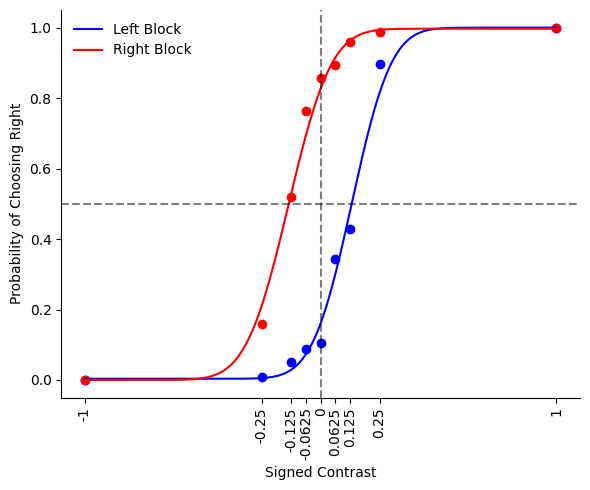

In [6]:
params, fig = plot_population_psychometric_by_block_pooled(meta_df)

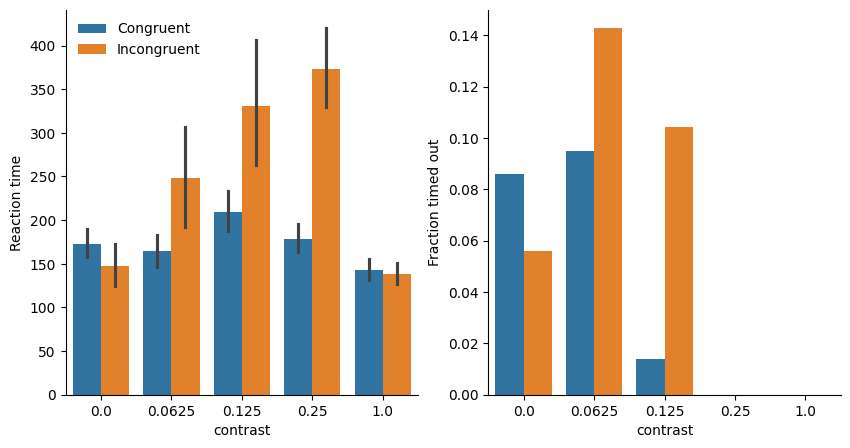

In [7]:
reaction_time_plots(meta_df, train_cfg.env.T_max)

In [8]:
decode_results = decode_module_specificity(
    hidden_visual,
    hidden_motor,
    meta_df,
    trace_len,
    n_shuffles=100,
    epoch_fracs=(0, 0.2, 0.5, 0.8, 1),
)

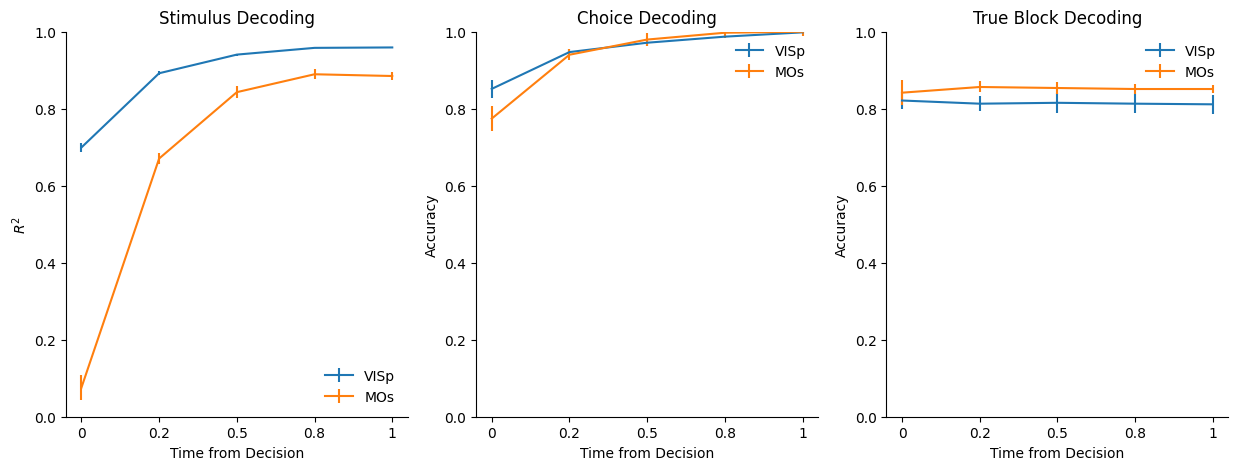

In [9]:
pretty_plot(decode_results)